<a href="https://colab.research.google.com/github/UH-RMDS-DataChallenge-2026/data-science-challenge/blob/main/Data_Science_Challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data Science Challenge – Town A (Seasonal / H3N2 Flu Vaccine) · Group B
**GitHub:** https://github.com/UH-RMDS-DataChallenge-2026 · **Target:** `seasonal_vaccine` (1 = will accept the vaccine)

**The problem.** The mayor must decide *who* receives a vaccine. Everyone will be infected (100 % infection). Each vaccine costs **$300** (also paid in cash to anyone who wants one but is not sent one) and each hospitalisation costs **$18,500**. Our goal is to **minimise the town's total cost**, not to maximise accuracy.

| Section | Content |
|---|---|
| 0 | Setup and configuration |
| 1 | Data loading and integrity checks |
| 2 | Exploratory Data Analysis (EDA) |
| 3 | The task-specific cost metric |
| 4 | Feature engineering and pre-processing |
| 5 | Pre-processing experiments |
| 6 | Model comparison (5-fold cross-validation) |
| 7 | Hyper-parameter tuning |
| 8 | Results, ranking and diagnostics |
| 9 | Sensitivity analysis of our assumptions |
| 10 | Submission files (top 5) |
| 11 | Explainable AI (XAI) |
| 12 | Summary for non-experts |

*This notebook merges the work of the whole team (EDA, baseline models, XGBoost/LightGBM and feature engineering, H3N2-specific vaccine effectiveness, holdout check and cost-based XAI, cost metric and sensitivity analysis).*

## 0. Setup and configuration

In [1]:
# Install gradient-boosting libraries and SHAP if they are missing (Colab usually has them)
%pip install -q xgboost lightgbm shap

In [2]:
# ---- Core libraries ----
import warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---- scikit-learn: pipelines, pre-processing, models, metrics ----
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import (roc_auc_score, log_loss, accuracy_score, brier_score_loss,
                             precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore")                  # keep the output readable
sns.set_theme(style="whitegrid")                   # consistent plot style
pd.set_option("display.max_columns", 100)          # show all columns in tables

RANDOM_STATE = 42                                  # one seed used everywhere -> reproducible results
np.random.seed(RANDOM_STATE); random.seed(RANDOM_STATE)

In [3]:
# ---- Data location: our GitHub repository (Raw files) ----
BASE = "https://raw.githubusercontent.com/UH-RMDS-DataChallenge-2026/data-science-challenge/main/"
TRAIN_FILE, TEST_FILE, SAMPLE_FILE = ("dataset_A_training.csv", "dataset_A_testing.csv",
                                      "dataset_A_example_submission.csv")

GROUP_NUMBER = "B"                     # our group ID, used in the submission file names
TARGET, ID_COL = "seasonal_vaccine", "respondent_id"

# ---- Town A costs (hackathon brief) ----
VACCINE_COST  = 300                    # $ per vaccine, also paid in cash if a vaccine is wanted but not sent
HOSPITAL_COST = 18_500                 # $ per hospitalisation (H3N2 flu)

# ---- Evaluation settings ----
N_FOLDS = 5                            # folds for cross-validation
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)   # same folds for every model

**1. Data loading and integrity checks**

In [4]:
import os
def load_csv(name):
    """Load a file from our GitHub repo; fall back to a local copy, then to a Colab upload prompt."""
    try:
        return pd.read_csv(BASE + name)                     # 1) GitHub Raw link
    except Exception:
        pass
    if os.path.exists(name):                                # 2) file already in the working directory
        return pd.read_csv(name)
    from google.colab import files as colab_files          # 3) ask the user to upload it
    print(f"Please upload {name}")
    uploaded = colab_files.upload()
    return pd.read_csv(next(iter(uploaded)))

train  = load_csv(TRAIN_FILE)          # past survey with the target
test   = load_csv(TEST_FILE)           # town residents we must decide for (no target)
sample = load_csv(SAMPLE_FILE)         # required submission format

print("Training:", train.shape, "| Testing:", test.shape, "| Example submission:", sample.shape)
display(train.head())

Training: (4756, 31) | Testing: (4749, 30) | Example submission: (4749, 2)


,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,doctor_recc_seasonal,child_under_6_months,health_worker,health_insurance,opinion_seas_vacc_effective,opinion_seas_risk,opinion_seas_sick_from_vacc,age_group,education,race,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
0,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,4.0,2.0,18 - 34 Years,12 Years,White,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,entertainment,0,0
1,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0,4.0,4.0,18 - 34 Years,Some College,White,Male,NaN,Not Married,Rent,Employed,"MSA, Principle City",1.0,0.0,education,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,4.0,2.0,1.0,65+ Years,College Graduate,White,Male,"> $75,000",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,NaN,0,0
3,4,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,NaN,0.0,0.0,1.0,3.0,3.0,1.0,55 - 64 Years,College Graduate,White,Male,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",1.0,2.0,utilities,0,1
4,5,2.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,NaN,3.0,1.0,1.0,55 - 64 Years,12 Years,White,Female,Below Poverty,Not Married,Rent,Not in Labor Force,"MSA, Not Principle City",2.0,0.0,NaN,1,0


In [5]:
# Integrity checks: duplicates, missing target, train/test overlap, submission format
print("Duplicate respondent IDs :", train[ID_COL].duplicated().sum())
print("Duplicate rows           :", train.duplicated().sum())
print("Missing target values    :", train[TARGET].isnull().sum())
print("IDs shared train & test  :", len(set(train[ID_COL]) & set(test[ID_COL])))
print("Same features train/test :", set(train.columns) - {TARGET} == set(test.columns))
print("Example submission cols  :", sample.columns.tolist(), "| values:", sorted(sample[TARGET].unique()))
assert test[ID_COL].equals(sample[ID_COL]), "Test IDs must match the example submission order"

Duplicate respondent IDs : 0
Duplicate rows           : 0
Missing target values    : 0
IDs shared train & test  : 0
Same features train/test : True
Example submission cols  : ['respondent_id', 'seasonal_vaccine'] | values: [np.float64(0.0)]


**Interpretation.** The data is clean structurally: no duplicates, no missing target values, no overlap between training and test respondents, and identical feature sets. The example submission contains 0/1 values, so we must submit decisions (send / don't send a vaccine), not probabilities.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Data types and summary statistics

In [6]:
train.info()
display(train.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4756 entries, 0 to 4755
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   respondent_id                  4756 non-null   int64  
 1   flu_concern                    4744 non-null   float64
 2   flu_knowledge                  4733 non-null   float64
 3   behavioral_antiviral_meds      4742 non-null   float64
 4   behavioral_avoidance           4724 non-null   float64
 5   behavioral_face_mask           4753 non-null   float64
 6   behavioral_wash_hands          4748 non-null   float64
 7   behavioral_large_gatherings    4747 non-null   float64
 8   behavioral_outside_home        4747 non-null   float64
 9   behavioral_touch_face          4737 non-null   float64
 10  doctor_recc_seasonal           4435 non-null   float64
 11  child_under_6_months           4604 non-null   float64
 12  health_worker                  4607 non-null   f

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
respondent_id,4756.0,NaN,NaN,NaN,2378.5,1373.08327,1.0,1189.75,2378.5,3567.25,4756.0
flu_concern,4744.0,NaN,NaN,NaN,1.643128,0.91981,0.0,1.0,2.0,2.0,3.0
flu_knowledge,4733.0,NaN,NaN,NaN,1.293049,0.618902,0.0,1.0,1.0,2.0,2.0
behavioral_antiviral_meds,4742.0,NaN,NaN,NaN,0.052299,0.222652,0.0,0.0,0.0,0.0,1.0
behavioral_avoidance,4724.0,NaN,NaN,NaN,0.734124,0.441846,0.0,0.0,1.0,1.0,1.0
behavioral_face_mask,4753.0,NaN,NaN,NaN,0.073848,0.261551,0.0,0.0,0.0,0.0,1.0
behavioral_wash_hands,4748.0,NaN,NaN,NaN,0.836563,0.369803,0.0,1.0,1.0,1.0,1.0
behavioral_large_gatherings,4747.0,NaN,NaN,NaN,0.365494,0.481619,0.0,0.0,0.0,1.0,1.0
behavioral_outside_home,4747.0,NaN,NaN,NaN,0.336634,0.472608,0.0,0.0,0.0,1.0,1.0
behavioral_touch_face,4737.0,NaN,NaN,NaN,0.68841,0.463192,0.0,0.0,1.0,1.0,1.0


### 2.2 Missing values

,Missing (train),% (train),% (test)
employment_sector,2314,48.65,50.64
health_insurance,1925,40.48,41.74
income_poverty,790,16.61,16.78
rent_or_own,381,8.01,7.98
doctor_recc_seasonal,321,6.75,7.26
education,270,5.68,5.66
employment_status,269,5.66,5.83
marital_status,265,5.57,5.66
child_under_6_months,152,3.20,3.26
health_worker,149,3.13,3.14


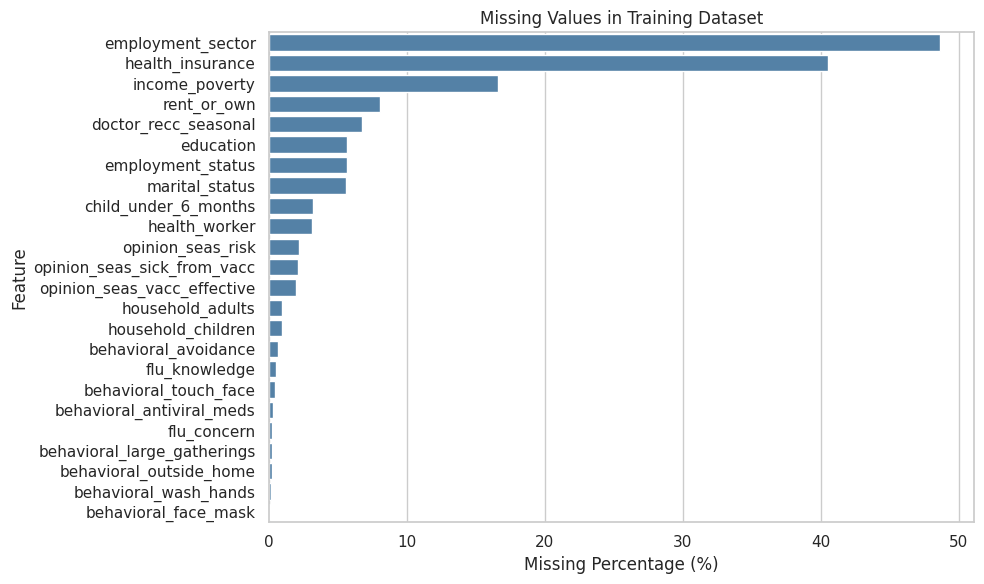

In [7]:
# Count and percentage of missing values per column (training and testing)
missing = pd.DataFrame({
    "Missing (train)": train.isnull().sum(),
    "% (train)": train.isnull().mean() * 100,
    "% (test)": test.isnull().mean() * 100,
})
missing = missing[missing["Missing (train)"] > 0].sort_values("% (train)", ascending=False)
display(missing.round(2))

plt.figure(figsize=(10, 6))
sns.barplot(x=missing["% (train)"], y=missing.index, color="steelblue")
plt.title("Missing Values in Training Dataset"); plt.xlabel("Missing Percentage (%)"); plt.ylabel("Feature")
plt.tight_layout(); plt.show()

**Interpretation.** `employment_sector` (49 %) and `health_insurance` (40 %) are heavily missing, with the **same pattern in the test set**. Because `health_insurance` is one of the most informative features (see 2.6), we **do not drop it**: we impute it and add a "was missing" flag, so the model can learn whether missingness itself carries information. All other features are under 17 % missing.

### 2.3 Target distribution

seasonal_vaccine
1    2551
0    2205
Name: count, dtype: int64 

seasonal_vaccine
1    53.64
0    46.36
Name: proportion, dtype: float64


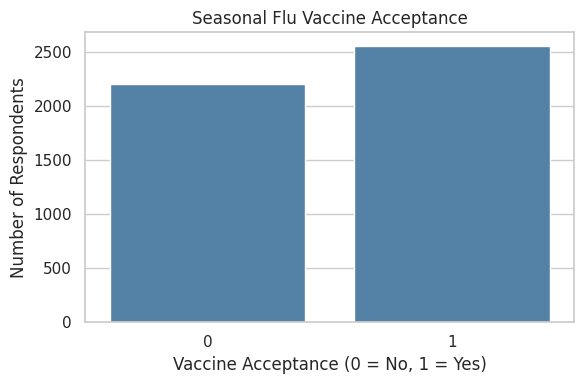

In [8]:
counts = train[TARGET].value_counts()
print(counts, "\n")
print((train[TARGET].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=train, x=TARGET, color="steelblue")
plt.title("Seasonal Flu Vaccine Acceptance"); plt.xlabel("Vaccine Acceptance (0 = No, 1 = Yes)")
plt.ylabel("Number of Respondents"); plt.tight_layout(); plt.show()

**Interpretation.** The classes are balanced (53.6 % accept, 46.4 % refuse), so no resampling or class weighting is needed. Guessing "yes" for everyone would be 53.6 % accurate – our baseline for accuracy.

### 2.4 Acceptance by age, doctor's recommendation and chronic conditions

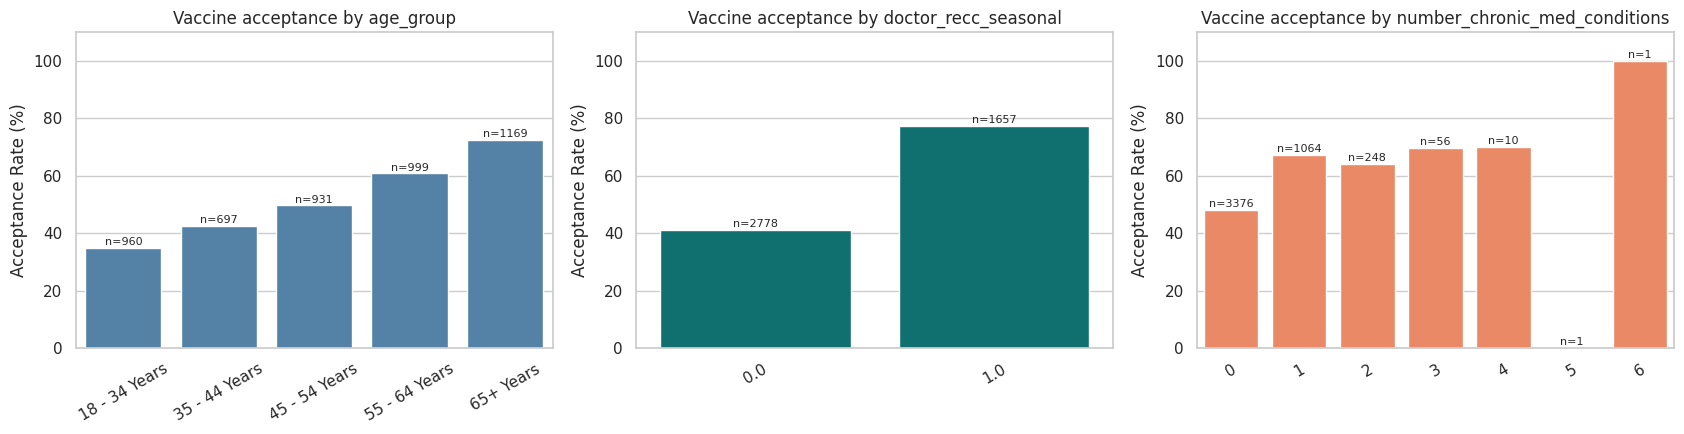

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, feat, colour in zip(axes, ["age_group", "doctor_recc_seasonal", "number_chronic_med_conditions"],
                            ["steelblue", "teal", "coral"]):
    rate = train.groupby(feat)[TARGET].mean() * 100            # acceptance rate per category
    n = train.groupby(feat)[TARGET].size()                     # how many people per category
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color=colour)
    for i, (r, c) in enumerate(zip(rate.values, n.values)):     # annotate group sizes (small groups are unreliable)
        ax.text(i, r + 1, f"n={c}", ha="center", fontsize=8)
    ax.set_title(f"Vaccine acceptance by {feat}"); ax.set_ylabel("Acceptance Rate (%)"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30); ax.set_ylim(0, 110)
plt.tight_layout(); plt.show()

**Interpretation.**
- **Age:** acceptance rises steadily from **35 % (18–34) to 73 % (65+)**. Older people are also the most expensive to leave unprotected, which matters for the cost metric.
- **Doctor's recommendation:** **78 % accept with a recommendation vs 41 % without** – the clearest single effect.
- **Chronic conditions:** 48 % with none vs 64–70 % with one or more. The 0 % and 100 % bars for 5–6 conditions are based on **one person each** (n=1) and must not be interpreted as real patterns.

2.5 Opinions about the vaccine

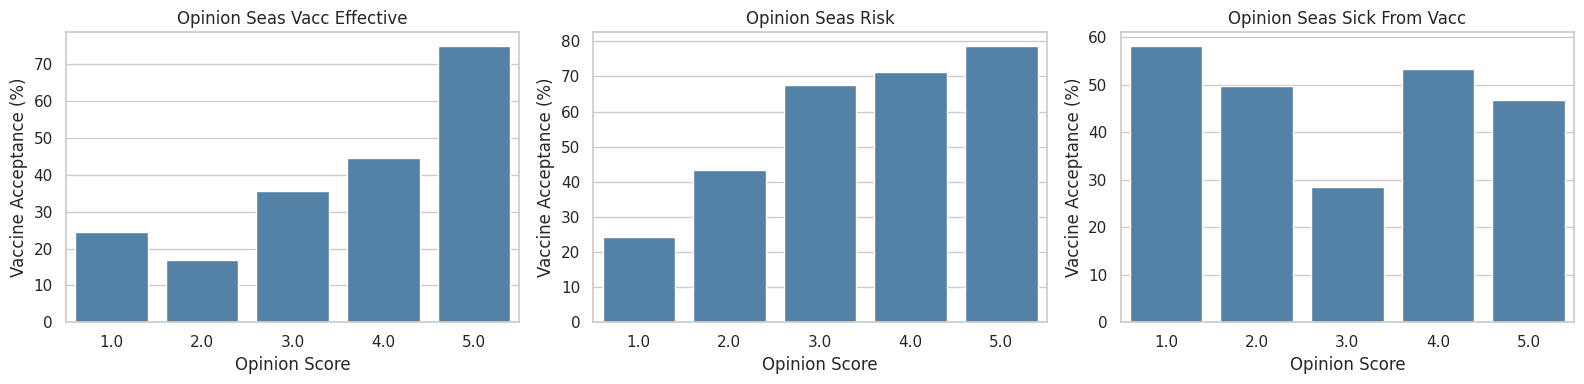

In [10]:
opinion_features = ["opinion_seas_vacc_effective", "opinion_seas_risk", "opinion_seas_sick_from_vacc"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, feature in zip(axes, opinion_features):
    acceptance = train.groupby(feature)[TARGET].mean() * 100   # acceptance per opinion score (1-5)
    sns.barplot(x=acceptance.index, y=acceptance.values, ax=ax, color="steelblue")
    ax.set_title(feature.replace("_", " ").title()); ax.set_xlabel("Opinion Score"); ax.set_ylabel("Vaccine Acceptance (%)")
plt.tight_layout(); plt.show()

**Interpretation.** Acceptance rises strongly with perceived **risk of flu** and perceived **vaccine effectiveness**, while worry about getting sick from the vaccine has a weaker effect. Note that score **3 means "Don't know"**, which is not genuinely "between" 2 and 4 – we therefore test treating these scales as categories (Section 5).

### 2.6 Demographic features

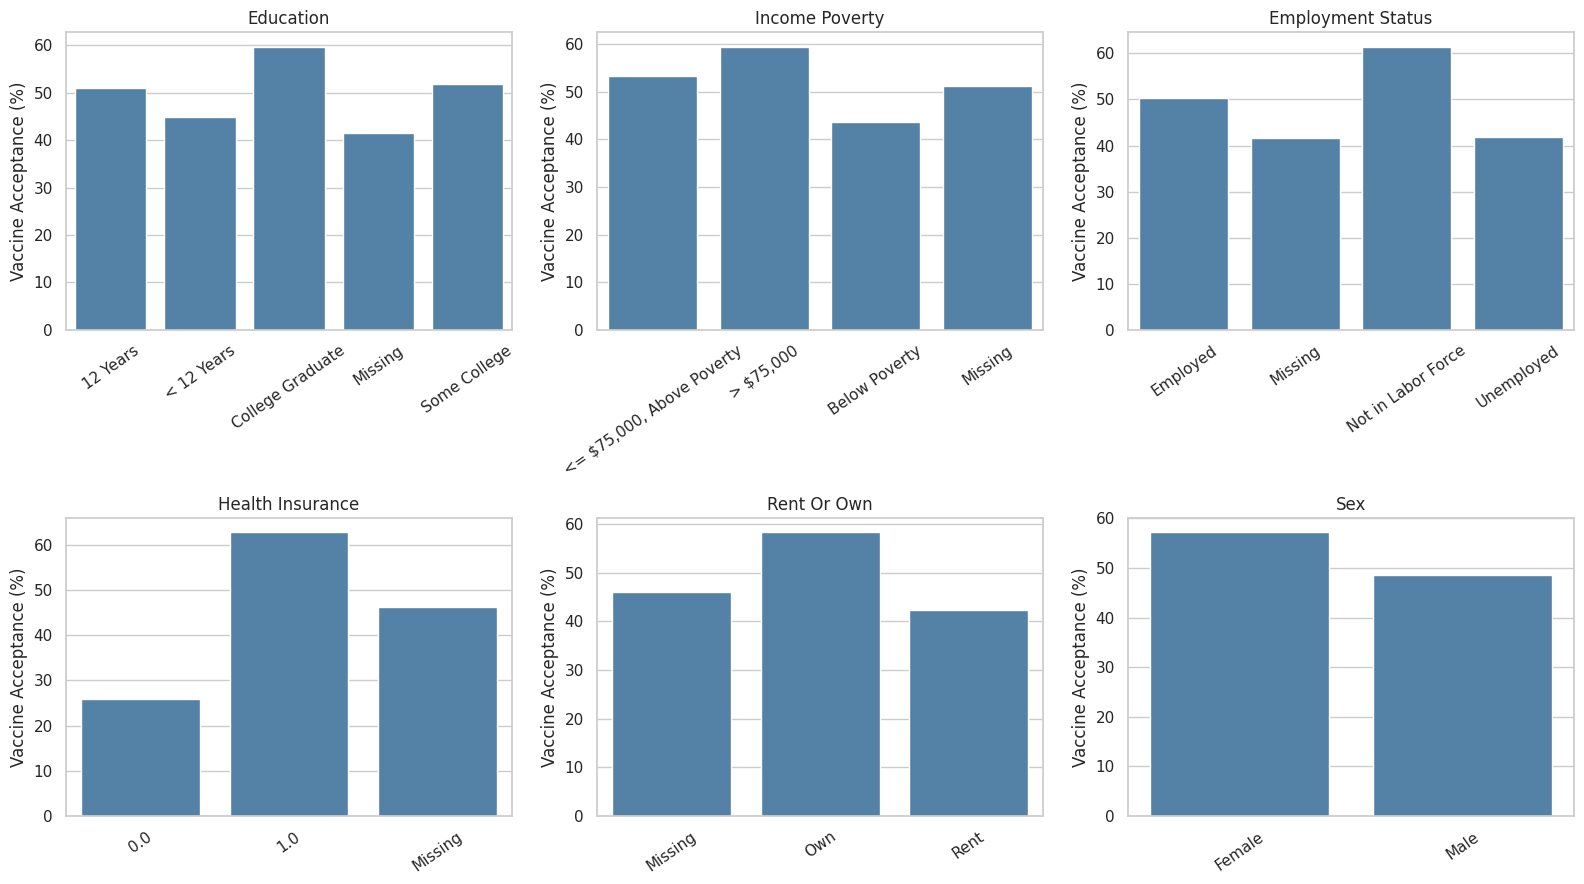

In [11]:
features = ["education", "income_poverty", "employment_status", "health_insurance", "rent_or_own", "sex"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, feature in zip(axes.flat, features):
    data = train.copy()
    data[feature] = data[feature].astype("string").fillna("Missing")        # show missing as its own bar
    summary = data.groupby(feature)[TARGET].mean().mul(100).reset_index(name="acceptance_rate")
    sns.barplot(data=summary, x=feature, y="acceptance_rate", color="steelblue", ax=ax)
    ax.set_title(feature.replace("_", " ").title()); ax.set_xlabel(""); ax.set_ylabel("Vaccine Acceptance (%)")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

**Interpretation.** People **with health insurance** accept far more often, and – importantly – the **"Missing" insurance group behaves differently** from both "Yes" and "No", confirming that a missing-value flag is useful. Higher education and income are associated with higher uptake; differences by sex and housing are smaller.

### 2.7 Age and chronic conditions together

Number of respondents in each group:


number_chronic_med_conditions,0,1,2,3,4,5,6
age_group,,,,,,,
18 - 34 Years,803,123,27,6,1,0,0
35 - 44 Years,548,118,24,5,1,0,1
45 - 54 Years,705,177,37,10,2,0,0
55 - 64 Years,652,261,71,12,2,1,0
65+ Years,668,385,89,23,4,0,0


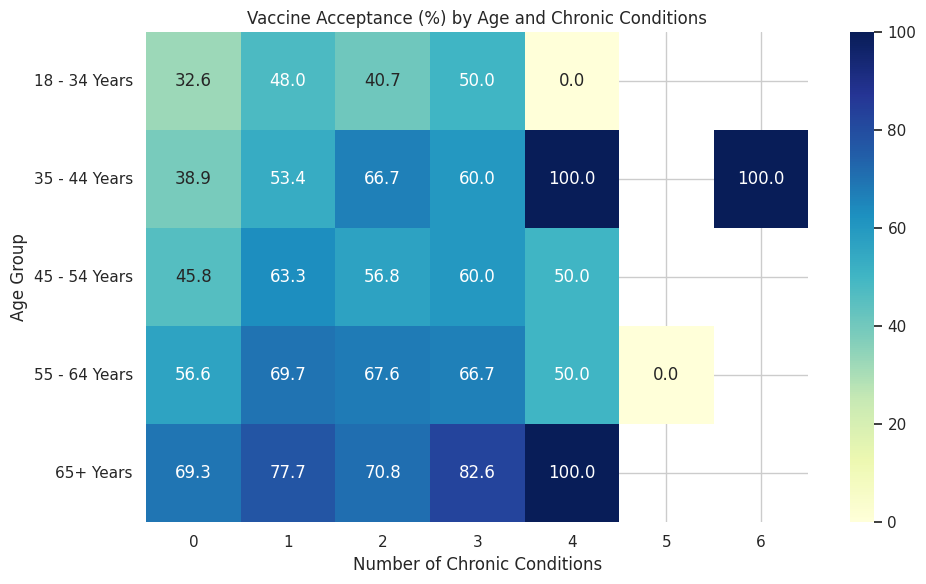

In [12]:
age_chronic = train.pivot_table(index="age_group", columns="number_chronic_med_conditions",
                                values=TARGET, aggfunc="mean") * 100           # acceptance rate per cell
age_chronic_n = train.pivot_table(index="age_group", columns="number_chronic_med_conditions",
                                  values=TARGET, aggfunc="count").fillna(0).astype(int)  # people per cell
print("Number of respondents in each group:"); display(age_chronic_n)

plt.figure(figsize=(10, 6))
sns.heatmap(age_chronic, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0, vmax=100)
plt.title("Vaccine Acceptance (%) by Age and Chronic Conditions")
plt.xlabel("Number of Chronic Conditions"); plt.ylabel("Age Group"); plt.tight_layout(); plt.show()

**Interpretation.** Age and chronic conditions both increase acceptance **independently**: within every age group, people with one condition accept more than those with none. Cells with 4+ conditions contain only 1–4 people, so their extreme values are noise. These are also the two factors that determine hospitalisation risk in our cost metric.

### 2.8 Correlations

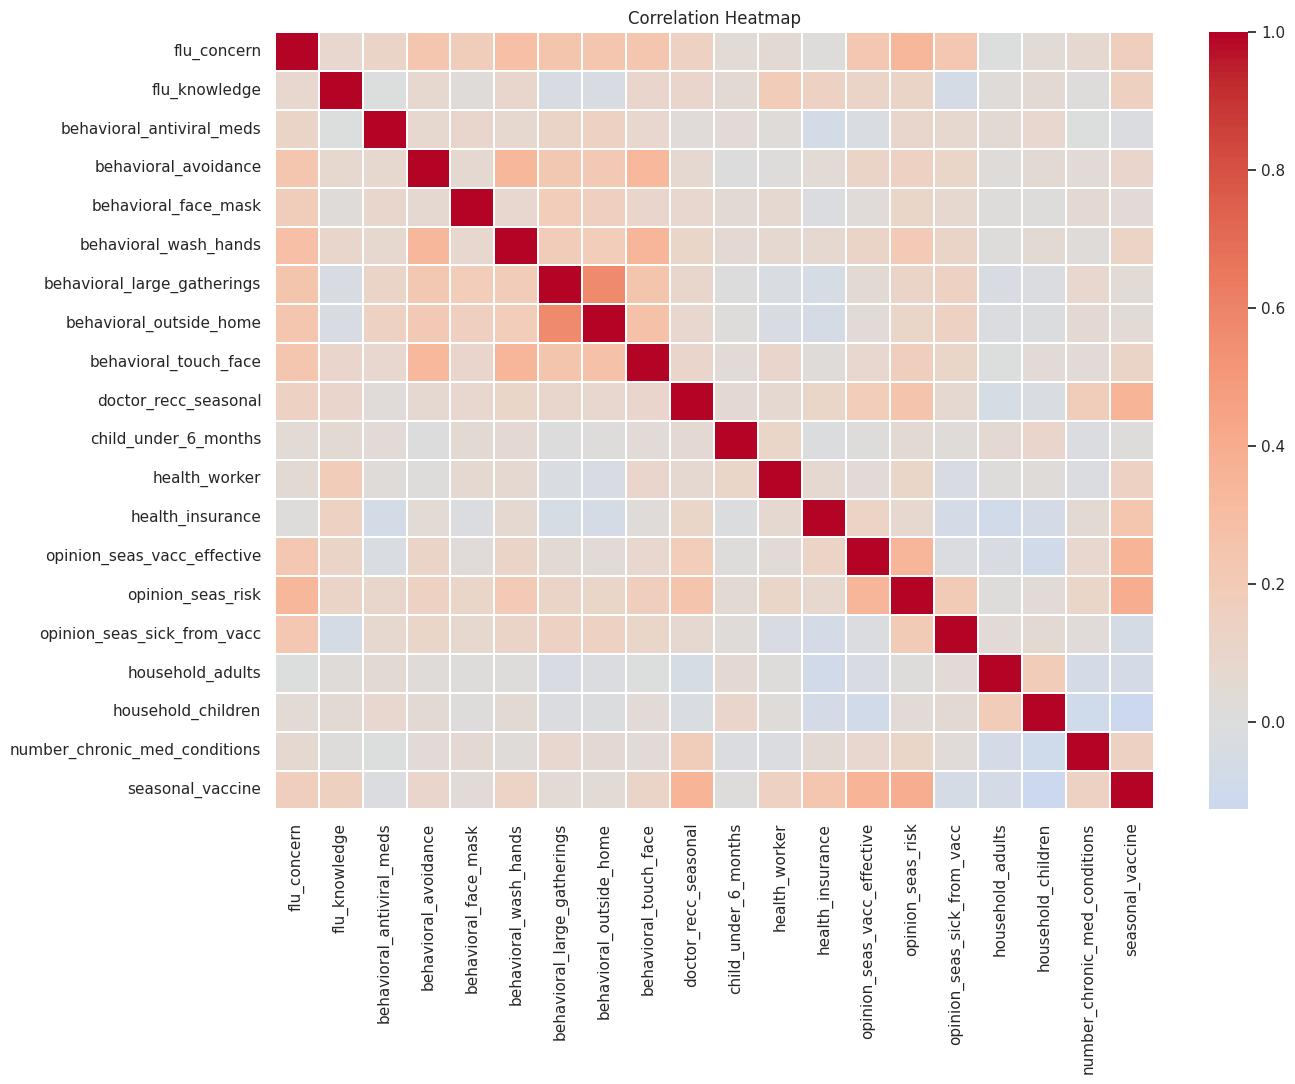

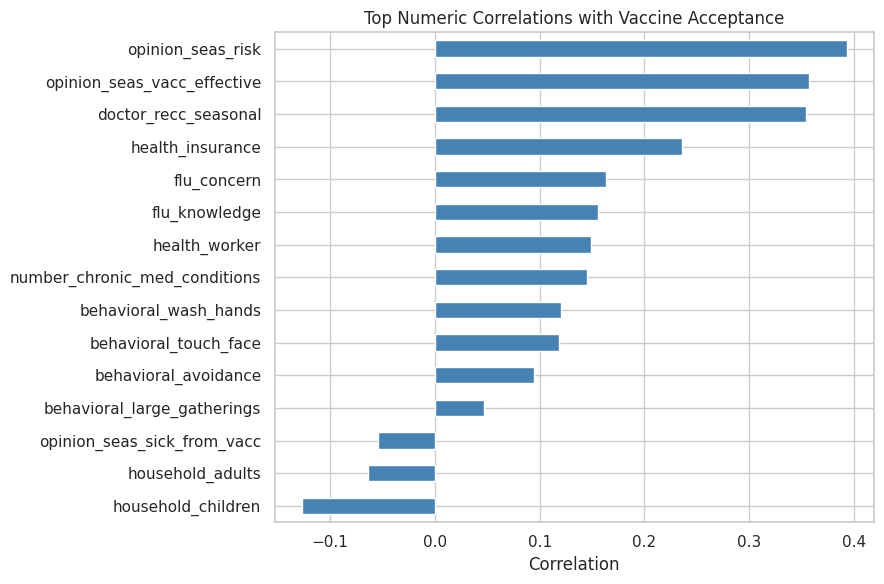

,Correlation
opinion_seas_risk,0.393
opinion_seas_vacc_effective,0.357
doctor_recc_seasonal,0.355
health_insurance,0.236
flu_concern,0.164
flu_knowledge,0.156
health_worker,0.149
number_chronic_med_conditions,0.145
household_children,-0.127
behavioral_wash_hands,0.120


In [13]:
numeric_data = train.select_dtypes(include="number").drop(columns=[ID_COL])
correlation = numeric_data.corr()                                   # Pearson correlation matrix

plt.figure(figsize=(14, 11))
sns.heatmap(correlation, cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Correlation Heatmap"); plt.tight_layout(); plt.show()

target_corr = correlation[TARGET].drop(TARGET)
target_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)
plt.figure(figsize=(9, 6))
target_corr.head(15).sort_values().plot(kind="barh", color="steelblue")
plt.title("Top Numeric Correlations with Vaccine Acceptance"); plt.xlabel("Correlation")
plt.tight_layout(); plt.show()
display(target_corr.to_frame("Correlation").round(3))

**Interpretation.** The strongest linear associations are **perceived flu risk (0.39)**, **perceived vaccine effectiveness (0.36)**, **doctor's recommendation (0.35)** and **health insurance (0.24)**. No single feature dominates, so a model combining many features is needed. Correlations between predictors are moderate, so multicollinearity is not a concern.

## 3. The task-specific cost metric

Everyone is infected. For a person with hospitalisation probability *h* (if unvaccinated) and vaccine effectiveness *VE* against hospitalisation:

| | Wants vaccine (y = 1) | Does not want it (y = 0) |
|---|---|---|
| **Sent (predict 1)** | 300 + h·(1 − VE)·18,500 (protected) | 300 + h·18,500 (wasted vaccine) |
| **Not sent (predict 0)** | 300 + h·18,500 (town pays cash, person unprotected) | h·18,500 |

**Total cost = sum over all people – lower is better.**

**Our assumptions (researched with generative AI, cross-checked across team members, as encouraged in the brief):**
- **Hospitalisation probability per infection by age**, from CDC burden estimates (hospitalisations ÷ symptomatic illnesses, H3N2-dominant season 2017-18): 18–44 ≈ 0.56 %, 45–54 ≈ 0.8 %, 55–64 ≈ 1.06 %, 65+ ≈ 9 %.
- **Chronic conditions** multiply risk by (1 + number of conditions) – a stated, simple assumption.
- **Vaccine effectiveness against hospitalisation:** VE = 0.40 (CDC: ≈ 41–61 %; H3N2 vaccines tend to the lower end).
- An **alternative set of literature estimates** from one of our team members (lower 65+ risk of 2.5 %, VE 0.22 for 65+) is tested in Section 9.

**Optimal decision rule.** Sending is worth it only if the expected hospital saving exceeds the expected vaccine waste:

$$\text{send if } P(\text{wants}) > \frac{300}{300 + 18{,}500 \cdot h \cdot VE}$$

So the threshold is **personal**: high (≈ 0.88) for young healthy people, low (≈ 0.1–0.3) for older or chronically ill people.


In [14]:
VE = 0.40                                                    # vaccine effectiveness against hospitalisation
AGE_RISK = {"18": 0.0056, "35": 0.0056, "45": 0.008, "55": 0.0106, "65": 0.09}   # keyed by first 2 chars of age_group

def hosp_prob(df, age_risk=AGE_RISK, chronic_mult=1.0):
    """Per-person hospitalisation probability if unvaccinated: age risk x (1 + k * chronic conditions)."""
    base = df["age_group"].astype(str).str[:2].map(age_risk).fillna(0.0056)
    n_chronic = df["number_chronic_med_conditions"].fillna(0)
    return (base * (1 + chronic_mult * n_chronic)).clip(upper=1.0).to_numpy()

def cost_per_person(y_true, send, h, ve=VE):
    """Average $ cost per person for send(1)/don't-send(0) decisions. ve may be a number or an array."""
    y_true, send = np.asarray(y_true), np.asarray(send)
    cost = np.where(send == 1,
                    VACCINE_COST + np.where(y_true == 1, h * (1 - ve), h) * HOSPITAL_COST,   # vaccine sent
                    np.where(y_true == 1, VACCINE_COST, 0) + h * HOSPITAL_COST)            # not sent
    return cost.mean()

def personal_threshold(h, ve=VE):
    """Probability above which sending a vaccine reduces expected cost."""
    return VACCINE_COST / (VACCINE_COST + HOSPITAL_COST * h * ve)

h_train, h_test = hosp_prob(train), hosp_prob(test)
y = train[TARGET].astype(int).to_numpy()

# Sanity check: perfect decisions must beat random decisions
rng = np.random.default_rng(RANDOM_STATE)
assert cost_per_person(y, y, h_train) < cost_per_person(y, rng.integers(0, 2, len(y)), h_train)

# Personal thresholds for typical people
for age in ["18 - 34 Years", "55 - 64 Years", "65+ Years"]:
    for n in [0, 1]:
        h = hosp_prob(pd.DataFrame({"age_group": [age], "number_chronic_med_conditions": [n]}))[0]
        print(f"{age:15s} | {n} chronic condition(s) | h = {h:.4f} | send if P(wants) > {personal_threshold(h):.2f}")

18 - 34 Years   | 0 chronic condition(s) | h = 0.0056 | send if P(wants) > 0.88
18 - 34 Years   | 1 chronic condition(s) | h = 0.0112 | send if P(wants) > 0.78
55 - 64 Years   | 0 chronic condition(s) | h = 0.0106 | send if P(wants) > 0.79
55 - 64 Years   | 1 chronic condition(s) | h = 0.0212 | send if P(wants) > 0.66
65+ Years       | 0 chronic condition(s) | h = 0.0900 | send if P(wants) > 0.31
65+ Years       | 1 chronic condition(s) | h = 0.1800 | send if P(wants) > 0.18


In [15]:
# Baselines: what would the town pay without a model? (cost per person, $)
n = len(y)
baselines = {
    "Send to nobody":    cost_per_person(y, np.zeros(n), h_train),
    "Send to everybody": cost_per_person(y, np.ones(n),  h_train),
    "Perfect knowledge (lower bound)": cost_per_person(y, y, h_train),
}
display(pd.Series(baselines).round(2).to_frame("Cost per person ($)"))

,Cost per person ($)
Send to nobody,939.40
Send to everybody,859.69
Perfect knowledge (lower bound),720.60


**Interpretation.** Sending a vaccine to everybody is already cheaper than sending to nobody, but perfect knowledge would be far cheaper still. The gap between "send to nobody" and "perfect knowledge" is the **maximum saving a model can achieve**.

## 4. Feature engineering and pre-processing
Engineered features (team member's contribution) capture ordered categories, missingness and combined attitudes. All pre-processing happens **inside a scikit-learn `Pipeline`**, so imputation and scaling are fitted on the training folds only (no data leakage).


In [16]:
AGE_MAP = {"18 - 34 Years": 1, "35 - 44 Years": 2, "45 - 54 Years": 3, "55 - 64 Years": 4, "65+ Years": 5}
EDU_MAP = {"< 12 Years": 1, "12 Years": 2, "Some College": 3, "College Graduate": 4}
INC_MAP = {"Below Poverty": 1, "<= $75,000, Above Poverty": 2, "> $75,000": 3}
OPINION_COLS = ["opinion_seas_vacc_effective", "opinion_seas_risk", "opinion_seas_sick_from_vacc"]

def engineer(df):
    """Add engineered features (no blind fillna(0): missing values stay missing for the imputer)."""
    df = df.copy()
    df["age_group_ord"] = df["age_group"].map(AGE_MAP)                 # ordered categories -> numbers
    df["education_ord"] = df["education"].map(EDU_MAP)
    df["income_poverty_ord"] = df["income_poverty"].map(INC_MAP)
    for c in ["health_insurance", "employment_sector", "income_poverty", "education", "doctor_recc_seasonal"]:
        df[f"{c}_missing"] = df[c].isna().astype(int)                  # missingness flags
    behav = [c for c in df.columns if c.startswith("behavioral_")]
    df["behavioral_score"] = df[behav].sum(axis=1, min_count=1)        # how many protective behaviours
    df["opinion_mean"] = df[OPINION_COLS].mean(axis=1)
    df["vacc_intent"] = df["opinion_seas_vacc_effective"] - df["opinion_seas_sick_from_vacc"]
    df["risk_x_concern"] = df["opinion_seas_risk"] * df["flu_concern"]          # interactions
    df["doc_rec_x_concern"] = df["doctor_recc_seasonal"] * df["flu_concern"]
    df["household_total"] = df["household_adults"] + df["household_children"]
    df = df.drop(columns=["age_group", "education", "income_poverty"])          # replaced by ordinal versions
    int_cols = df.select_dtypes(include="integer").columns
    df[int_cols] = df[int_cols].astype(float)                                   # consistent float dtype (needed by PDP)
    return df

X_raw = train.drop(columns=[ID_COL, TARGET])            # original features
X_test_raw = test.drop(columns=[ID_COL])
X_eng = engineer(X_raw)                                 # engineered features
X_test_eng = engineer(X_test_raw)
print("Original features:", X_raw.shape[1], "| Engineered features:", X_eng.shape[1])

def make_preprocessor(X, num_imputer="median", scale=True, onehot_opinions=False, missing_indicator=False):
    """Column transformer: impute (+ scale) numeric columns, impute + one-hot categorical columns.
    num_imputer: 'median' or 'knn' | onehot_opinions: treat 1-5 opinion scales as categories
    missing_indicator: add 0/1 'was missing' columns for every numeric feature with gaps"""
    cat_cols = X.select_dtypes(exclude="number").columns.tolist()
    op_cols = [c for c in OPINION_COLS if onehot_opinions and c in X.columns]
    num_cols = [c for c in X.select_dtypes(include="number").columns if c not in op_cols]
    imputer = (KNNImputer(n_neighbors=5, add_indicator=missing_indicator) if num_imputer == "knn"
               else SimpleImputer(strategy="median", add_indicator=missing_indicator))
    num_pipe = Pipeline([("impute", imputer)] + ([("scale", StandardScaler())] if scale else []))
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),  # 'Missing' = own category
                         ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10))])
    parts = [("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)]
    if op_cols:
        parts.append(("opinions", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value=-1)),
                                            ("onehot", OneHotEncoder(handle_unknown="ignore"))]), op_cols))
    return ColumnTransformer(parts)

Original features: 29 | Engineered features: 40


## 5. Cross-validation framework and pre-processing experiments
Every model is evaluated with the **same 5 stratified folds**. For each fold we record AUC, log-loss, accuracy and the **town cost** under three decision rules:
1. **Fixed 0.5** threshold (standard classifier);
2. **Global threshold** – one cut-off chosen to minimise cost on the *training* fold, then applied to the validation fold (avoids optimistic bias);
3. **Personal threshold** – the risk-based rule from Section 3.

Out-of-fold probabilities (each person predicted by a model that never saw them) are stored for later analysis.

In [17]:
GRID = np.linspace(0.05, 0.95, 91)          # candidate global thresholds
OOF = {}                                    # out-of-fold probabilities per model
results = []                                # per-fold results for every model

def evaluate(name, model, X):
    """5-fold CV of one pipeline; stores out-of-fold probabilities and per-fold metrics."""
    oof = np.zeros(len(y))
    for fold, (tr, va) in enumerate(skf.split(X, y)):
        m = clone(model).fit(X.iloc[tr], y[tr])                       # fit on the training fold only
        p_tr, p_va = m.predict_proba(X.iloc[tr])[:, 1], m.predict_proba(X.iloc[va])[:, 1]
        oof[va] = p_va
        best_t = GRID[np.argmin([cost_per_person(y[tr], p_tr > t, h_train[tr]) for t in GRID])]
        results.append({
            "model": name, "fold": fold,
            "AUC": roc_auc_score(y[va], p_va), "log-loss": log_loss(y[va], p_va),
            "accuracy@0.5": accuracy_score(y[va], p_va > 0.5), "global_t": best_t,
            "cost | fixed 0.5": cost_per_person(y[va], p_va > 0.5, h_train[va]),
            "cost | global threshold": cost_per_person(y[va], p_va > best_t, h_train[va]),
            "cost | personal threshold": cost_per_person(y[va], p_va > personal_threshold(h_train[va]), h_train[va]),
            "precision (personal)": precision_score(y[va], p_va > personal_threshold(h_train[va]), zero_division=0),
            "recall (personal)": recall_score(y[va], p_va > personal_threshold(h_train[va])),
            "F1 (personal)": f1_score(y[va], p_va > personal_threshold(h_train[va])),
        })
    OOF[name] = oof
    r = pd.DataFrame([x for x in results if x["model"] == name]).mean(numeric_only=True)
    print(f"{name:45s} AUC {r['AUC']:.4f} | cost personal ${r['cost | personal threshold']:.2f} | acc {r['accuracy@0.5']:.3f}")

def summary_table(names=None):
    """Mean +/- std over folds for the chosen models."""
    df = pd.DataFrame(results)
    if names is not None:
        df = df[df.model.isin(names)]
    agg = df.drop(columns="fold").groupby("model").agg(["mean", "std"])
    return agg.sort_values(("cost | personal threshold", "mean")).round(4)

In [18]:
# Pre-processing experiments with Logistic Regression (fast, and sensitive to pre-processing choices)
def logreg(X, **prep_kwargs):
    """Logistic Regression pipeline with configurable pre-processing."""
    return Pipeline([("prep", make_preprocessor(X, **prep_kwargs)),
                     ("clf", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))])

experiments = {
    "LogReg | original, median impute":             (dict(X=X_raw), X_raw),
    "LogReg | original, KNN impute":                (dict(X=X_raw, num_imputer="knn"), X_raw),
    "LogReg | original, opinions one-hot + flags":  (dict(X=X_raw, onehot_opinions=True, missing_indicator=True), X_raw),
    "LogReg | engineered, median impute":           (dict(X=X_eng), X_eng),
    "LogReg | engineered, opinions one-hot":        (dict(X=X_eng, onehot_opinions=True), X_eng),
}
for name, (kwargs, X) in experiments.items():
    evaluate(name, logreg(**kwargs), X)

display(summary_table(list(experiments)))

LogReg | original, median impute              AUC 0.8460 | cost personal $762.13 | acc 0.777
LogReg | original, KNN impute                 AUC 0.8453 | cost personal $761.95 | acc 0.776
LogReg | original, opinions one-hot + flags   AUC 0.8506 | cost personal $760.95 | acc 0.777
LogReg | engineered, median impute            AUC 0.8488 | cost personal $762.52 | acc 0.778
LogReg | engineered, opinions one-hot         AUC 0.8521 | cost personal $760.76 | acc 0.776


AUC         log-loss          \
                                               mean     std     mean     std   
model                                                                          
LogReg | engineered, opinions one-hot        0.8521  0.0059   0.4803  0.0108   
LogReg | original, opinions one-hot + flags  0.8506  0.0046   0.4839  0.0082   
LogReg | original, KNN impute                0.8453  0.0016   0.4906  0.0037   
LogReg | original, median impute             0.8460  0.0029   0.4891  0.0056   
LogReg | engineered, median impute           0.8488  0.0050   0.4861  0.0097   

                                            accuracy@0.5         global_t  \
                                                    mean     std     mean   
model                                                                       
LogReg | engineered, opinions one-hot             0.7765  0.0069    0.508   
LogReg | original, opinions one-hot + flags       0.7767  0.0070    0.484   
LogReg | original, KNN impute                     0.7761  0.0067    0.524   
LogReg | original, median impute                  0.7769  0.0066    0.512   
LogReg | engineered, median impute                0.7775  0.0031    0.500   

                                                    cost | fixed 0.5           \
                                                std             mean      std   
model                                                                           
LogReg | engineered, opinions one-hot        0.0349         779.9302  38.7732   
LogReg | original, opinions one-hot + flags  0.0397         778.1754  40.1872   
LogReg | original, KNN impute                0.0321         776.0608  39.5773   
LogReg | original, median impute             0.0319         774.9698  38.4155   
LogReg | engineered, median impute           0.0367         778.2350  39.2714   

                                            cost | global threshold           \
                                                               mean      std   
model                                                                          
LogReg | engineered, opinions one-hot                      781.8331  37.0398   
LogReg | original, opinions one-hot + flags                778.6872  40.0960   
LogReg | original, KNN impute                              776.2300  39.9854   
LogReg | original, median impute                           775.7428  38.8588   
LogReg | engineered, median impute                         780.6996  38.2729   

                                            cost | personal threshold  \
                                                                 mean   
model                                                                   
LogReg | engineered, opinions one-hot                        760.7606   
LogReg | original, opinions one-hot + flags                  760.9517   
LogReg | original, KNN impute                                761.9507   
LogReg | original, median impute                             762.1276   
LogReg | engineered, median impute                           762.5239   

                                                     precision (personal)  \
                                                 std                 mean   
model                                                                       
LogReg | engineered, opinions one-hot        38.4147               0.8167   
LogReg | original, opinions one-hot + flags  39.2197               0.8134   
LogReg | original, KNN impute                38.7172               0.8060   
LogReg | original, median impute             39.4759               0.8039   
LogReg | engineered, median impute           38.9098               0.8089   

                                                    recall (personal)          \
                                                std              mean     std   
model                                                                           
LogReg | engineered, opinions one-hot        0.0137    

**Interpretation.** All pre-processing variants perform within a narrow band. The choices that help most are those that respect the meaning of the data: treating the opinion scales as categories ("3 = Don't know" is not a midpoint) and keeping missingness information. Median vs KNN imputation makes almost no difference, so we use the simpler, faster median imputation for the model comparison.

## 8. Results, ranking and diagnostics

We compare and rank models using their mean cross-validated cost per person across three decision rules: fixed (0.5), global and personalised thresholds. We assess average cost, consistency across folds and cost savings against the send-to-nobody baseline to identify the most cost-effective model.

In [27]:
# Every (model, decision rule) combination ranked by mean cross-validated cost per person
res = pd.DataFrame(results)
rule_cols = ["cost | fixed 0.5", "cost | global threshold", "cost | personal threshold"]
long = res.melt(id_vars=["model", "fold"], value_vars=rule_cols, var_name="rule", value_name="cost")
long["rule"] = long["rule"].str.replace("cost | ", "", regex=False)
ranking = long.groupby(["model", "rule"])["cost"].agg(["mean", "std"]).sort_values("mean").reset_index()
ranking["saving vs send-to-nobody ($/person)"] = baselines["Send to nobody"] - ranking["mean"]
ranking["% of maximum possible saving"] = 100 * ranking["saving vs send-to-nobody ($/person)"] / (
    baselines["Send to nobody"] - baselines["Perfect knowledge (lower bound)"])
display(ranking.head(15).round(2))

,model,rule,mean,std,saving vs send-to-nobody ($/person),% of maximum possible saving
0,"LogReg | engineered, opinions one-hot",personal threshold,760.76,38.41,178.64,81.64
1,"LogReg | original, opinions one-hot + flags",personal threshold,760.95,39.22,178.45,81.56
2,"LogReg | original, KNN impute",personal threshold,761.95,38.72,177.45,81.10
3,"LogReg | original, median impute",personal threshold,762.13,39.48,177.27,81.02
4,"LogReg | engineered, median impute",personal threshold,762.52,38.91,176.87,80.84
5,"LogReg | original, median impute",fixed 0.5,774.97,38.42,164.43,75.15
6,"LogReg | original, median impute",global threshold,775.74,38.86,163.65,74.80
7,"LogReg | original, KNN impute",fixed 0.5,776.06,39.58,163.34,74.65
8,"LogReg | original, KNN impute",global threshold,776.23,39.99,163.17,74.57
9,"LogReg | original, opinions one-hot + flags",fixed 0.5,778.18,40.19,161.22,73.69


,AUC,log-loss,accuracy@0.5,precision (personal),recall (personal),F1 (personal),cost | fixed 0.5,cost | global threshold,cost | personal threshold
model,,,,,,,,,
"LogReg | engineered, opinions one-hot",0.8521,0.4803,0.7765,0.8167,0.6088,0.6973,779.9302,781.8331,760.7606
"LogReg | original, opinions one-hot + flags",0.8506,0.4839,0.7767,0.8134,0.6041,0.6929,778.1754,778.6872,760.9517
"LogReg | original, KNN impute",0.8453,0.4906,0.7761,0.8060,0.5884,0.6800,776.0608,776.2300,761.9507
"LogReg | original, median impute",0.8460,0.4891,0.7769,0.8039,0.5892,0.6797,774.9698,775.7428,762.1276
"LogReg | engineered, median impute",0.8488,0.4861,0.7775,0.8089,0.6006,0.6891,778.2350,780.6996,762.5239


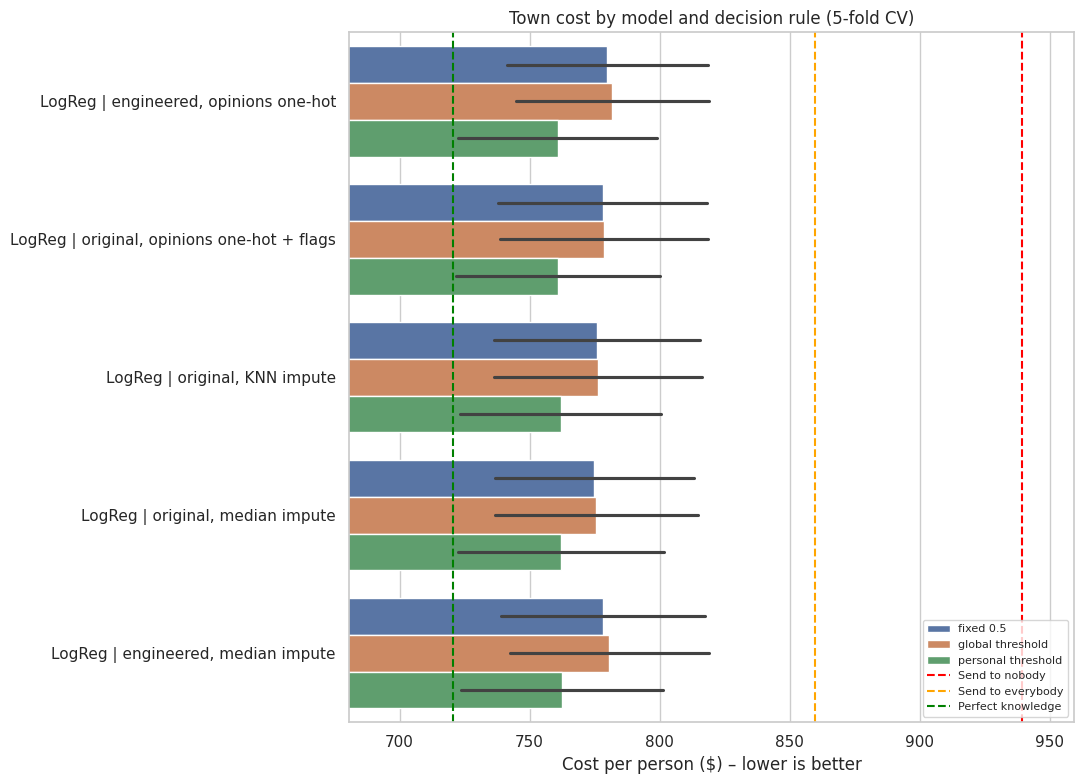

In [28]:
# Compact model table: discrimination, calibration, accuracy and cost under each rule
model_table = res.groupby("model")[["AUC", "log-loss", "accuracy@0.5", "precision (personal)",
                                    "recall (personal)", "F1 (personal)"] + rule_cols].mean()
model_table = model_table.sort_values("cost | personal threshold").round(4)
display(model_table)

# Visual comparison of the decision rules for every model (mean +/- std over folds)
plot_df = long.copy()
order = model_table.index.tolist()
plt.figure(figsize=(11, 8))
sns.barplot(data=plot_df, y="model", x="cost", hue="rule", order=order, errorbar="sd")
for label, val, col in [("Send to nobody", baselines["Send to nobody"], "red"),
                        ("Send to everybody", baselines["Send to everybody"], "orange"),
                        ("Perfect knowledge", baselines["Perfect knowledge (lower bound)"], "green")]:
    plt.axvline(val, ls="--", color=col, label=label)
plt.xlim(baselines["Perfect knowledge (lower bound)"] - 40, baselines["Send to nobody"] + 20)
plt.xlabel("Cost per person ($) – lower is better"); plt.ylabel("")
plt.title("Town cost by model and decision rule (5-fold CV)"); plt.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.** The **decision rule matters more than the model**: for every model, the personal (risk-based) threshold gives the lowest cost, beating the standard 0.5 cut-off. Differences between the best models are small compared with the fold-to-fold variation (± std), so the ranking among the top models is uncertain, while the advantage of the personal threshold is consistent. The single Decision Tree has clearly the lowest AUC and worst calibration, showing the benefit of ensembles; the personal rule partly compensates for this in cost.


In [29]:
# Is the personal-threshold advantage consistent? Paired comparison fold by fold
paired = res.assign(gain=res["cost | fixed 0.5"] - res["cost | personal threshold"])
display(paired.pivot(index="model", columns="fold", values="gain").round(2)
        .assign(mean=lambda d: d.mean(axis=1)).sort_values("mean", ascending=False))
print("Folds where the personal threshold beats 0.5:",
      f"{(paired['gain'] > 0).sum()} / {len(paired)}")

fold,0,1,2,3,4,mean
model,,,,,,
"LogReg | engineered, opinions one-hot",14.72,20.48,22.17,16.66,21.81,19.168
"LogReg | original, opinions one-hot + flags",15.17,16.00,21.98,12.99,19.97,17.222
"LogReg | engineered, median impute",13.69,16.94,18.84,13.60,15.49,15.712
"LogReg | original, KNN impute",11.52,12.99,18.18,10.14,17.72,14.110
"LogReg | original, median impute",15.19,11.53,10.81,10.97,15.71,12.842


Folds where the personal threshold beats 0.5: 25 / 25


### Final check on a held-out 20 %

Cross-validation reuses all data for model selection. As an independent check, we train on 80 % and evaluate the top candidates once on a **held-out 20 %** they have never seen (thresholds come from the assumptions, not from the holdout).

In [32]:
X_dev, X_hold, y_dev, y_hold, h_dev, h_hold, idx_dev, idx_hold = train_test_split(
    X_eng, y, h_train, np.arange(len(y)), test_size=0.2, stratify=y, random_state=RANDOM_STATE)
raw_dev, raw_hold = X_raw.iloc[idx_dev], X_raw.iloc[idx_hold]

def model_and_data(name):
    """Return the pipeline and the matching feature set (original or engineered)."""
    global_vars = globals()
    if "models" in global_vars and name in global_vars["models"]:
        return global_vars["models"][name], (X_dev, X_hold)
    if "tuned" in global_vars and name in global_vars["tuned"]:
        return global_vars["tuned"][name], (X_dev, X_hold)
    kwargs, Xset = experiments[name]
    return logreg(**kwargs), ((raw_dev, raw_hold) if Xset is X_raw else (X_dev, X_hold))

hold_rows = [{"model": "Send to nobody", "holdout cost": cost_per_person(y_hold, np.zeros(len(y_hold)), h_hold)},
             {"model": "Send to everybody", "holdout cost": cost_per_person(y_hold, np.ones(len(y_hold)), h_hold)}]
for name in model_table.index[:8]:
    mdl, (Xd, Xh) = model_and_data(name)
    p_h = clone(mdl).fit(Xd, y_dev).predict_proba(Xh)[:, 1]
    hold_rows.append({"model": name, "AUC": roc_auc_score(y_hold, p_h),
                      "holdout cost": cost_per_person(y_hold, p_h > personal_threshold(h_hold), h_hold),
                      "holdout cost @0.5": cost_per_person(y_hold, p_h > 0.5, h_hold),
                      "CV cost": model_table.loc[name, "cost | personal threshold"]})
display(pd.DataFrame(hold_rows).sort_values("holdout cost").round(3))

,model,holdout cost,AUC,holdout cost @0.5,CV cost
2,"LogReg | engineered, opinions one-hot",773.616,0.857,801.010,760.761
3,"LogReg | original, opinions one-hot + flags",775.544,0.858,794.732,760.952
6,"LogReg | engineered, median impute",777.291,0.851,798.374,762.524
4,"LogReg | original, KNN impute",777.893,0.845,795.486,761.951
5,"LogReg | original, median impute",778.022,0.848,793.805,762.128
1,Send to everybody,876.031,NaN,NaN,NaN
0,Send to nobody,968.003,NaN,NaN,NaN


**Interpretation.** The holdout confirms the cross-validation picture: every model beats both baselines on unseen people, and the personal threshold beats the 0.5 cut-off. Holdout costs differ slightly from CV costs because the holdout people differ (sampling noise), which is why we rank by the 5-fold CV average.

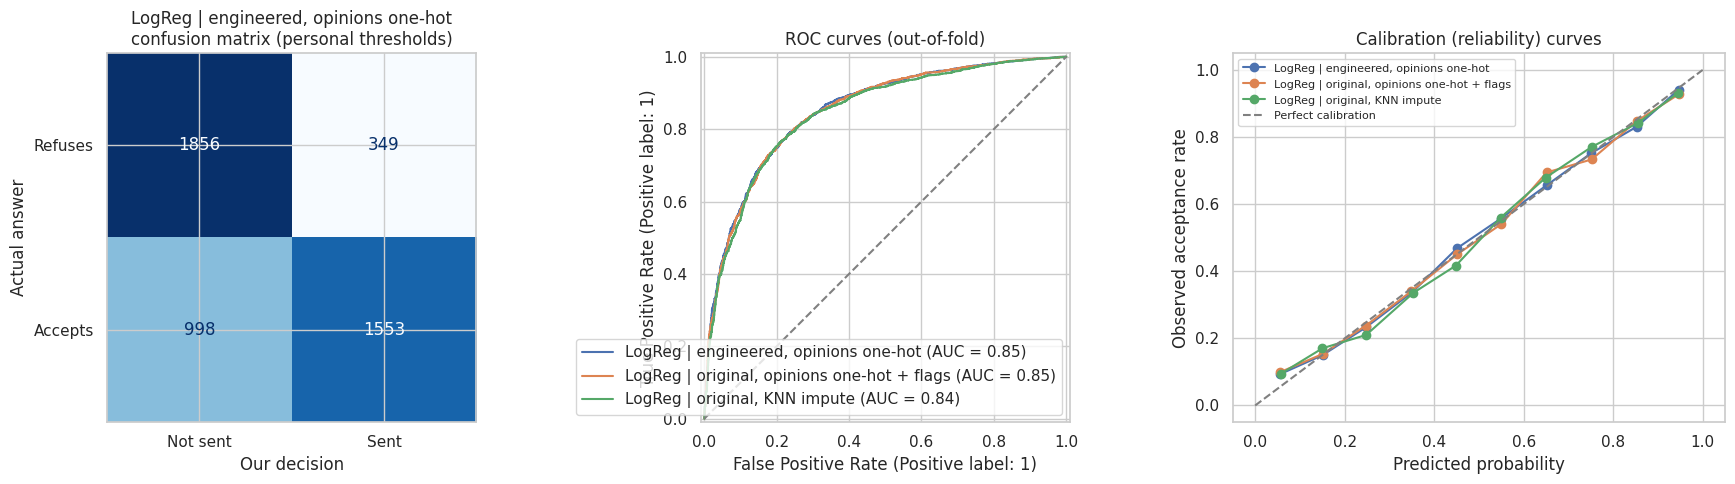

LogReg | engineered, opinions one-hot: accuracy@0.5 = 0.776 | accuracy with personal thresholds = 0.717 | Brier score = 0.1558


In [33]:
# Diagnostics for the best model: confusion matrix (personal rule), ROC curve and calibration
best_name = model_table.index[0]
p_best = OOF[best_name]
send_best = (p_best > personal_threshold(h_train)).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y, send_best, cmap="Blues", values_format="d", ax=axes[0], colorbar=False)
axes[0].set_xticklabels(["Not sent", "Sent"]); axes[0].set_yticklabels(["Refuses", "Accepts"])
axes[0].set_xlabel("Our decision"); axes[0].set_ylabel("Actual answer")
axes[0].set_title(f"{best_name}\nconfusion matrix (personal thresholds)")
for name in model_table.index[:3]:
    RocCurveDisplay.from_predictions(y, OOF[name], name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "--", color="grey"); axes[1].set_title("ROC curves (out-of-fold)")
for name in model_table.index[:3]:
    frac_pos, mean_pred = calibration_curve(y, OOF[name], n_bins=10)
    axes[2].plot(mean_pred, frac_pos, marker="o", label=name)
axes[2].plot([0, 1], [0, 1], "--", color="grey", label="Perfect calibration")
axes[2].set_xlabel("Predicted probability"); axes[2].set_ylabel("Observed acceptance rate")
axes[2].set_title("Calibration (reliability) curves"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"{best_name}: accuracy@0.5 = {accuracy_score(y, p_best > 0.5):.3f} | "
      f"accuracy with personal thresholds = {accuracy_score(y, send_best):.3f} | "
      f"Brier score = {brier_score_loss(y, p_best):.4f}")

**Interpretation.** The confusion matrix shows the rule's deliberate trade-off: many people who would accept are *not* sent a vaccine – mostly young, healthy people for whom a vaccine costs more ($300) than the hospital risk it removes. The calibration curves lie close to the diagonal, so the predicted probabilities can be trusted – a requirement for the personal-threshold rule. Accuracy with personal thresholds is *lower* than at 0.5 **by design**: the rule accepts more cheap mistakes (unused vaccines for high-risk people) to avoid expensive ones (unprotected high-risk people who wanted a vaccine). Accuracy treats all errors as equal; the town's budget does not.